In [1]:
# Imports and settings
import os
import sys
import numpy as np
import pandas as pd
from IPython import get_ipython
ipython = get_ipython()
if ipython is not None:
    ipython.run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from scipy.io import savemat

from Library import RBFLayer1, ListModule

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

torch.manual_seed(123)
np.random.seed(123)

Stable_A   = 1
multi_step = 1


Device: cpu


In [2]:
# Load one continuous segment; normalize using training data only.
from pathlib import Path

import zipfile

DATA_DIR = Path("New_Test_10132026")
DATA_FILE = DATA_DIR / "calibration_data.csv"
DATA_ARCHIVE = DATA_DIR / "2026-10-09 Real Flight Data (Group II UAV) 1.zip"
DATASET_NAME = "Tiguar_20261009_airspeed_until3420s"
MAX_TIME_SECONDS = 3420.0
actuator_columns = ["RCOU_C1", "RCOU_elv", "RCOU_rud"]
state_names = ["phi", "theta", "sin_psi", "cos_psi", "p", "q", "r", "airspeed"]
input_names = ["phiD", "thetaD", "sinpsiD", "cospsiD", "ThO"] + [
    name.removeprefix("RCOU_") for name in actuator_columns
]

# Read the supplied archive directly; extraction of the large BIN is unnecessary.
if DATA_FILE.is_file():
    df = pd.read_csv(DATA_FILE)
else:
    with zipfile.ZipFile(DATA_ARCHIVE) as archive:
        with archive.open(DATA_FILE.name) as csv_file:
            df = pd.read_csv(csv_file)

airspeed_column = "ARSP_Airspeed"
state_units = ["rad", "rad", "1", "1", "rad/s", "rad/s", "rad/s", "m/s"]
# Local interval identifier, not a supplied sensor-health segment label.
selected_segment = 0
sensor_health_status = "Unavailable: October CSV has no ARSP_H or ARSP_U flags"
print("Airspeed sensor health:", sensor_health_status)
time_column = next((name for name in ("t", "IMU_t") if name in df.columns), None)
if time_column is None:
    raise ValueError("The CSV must contain a time column named 't' or 'IMU_t' (seconds).")
# Filter before checking/modeling so the later project's data cannot enter any split.
log_time = pd.to_numeric(df[time_column], errors="coerce")
if not np.isfinite(log_time.to_numpy(dtype=float)).all():
    raise ValueError("The log contains missing/nonfinite timestamps; cannot apply cutoff safely.")
original_row_count = len(df)
df = df.loc[(log_time >= 0.0) & (log_time <= MAX_TIME_SECONDS)].copy()
print(f"Retained {len(df)} of {original_row_count} samples at 0 <= t <= {MAX_TIME_SECONDS:g} s")
# RCOU_elv/rud are already supplied; do not mix them again or subtract 1500.
required_columns = [
    time_column, "ATT_Roll", "ATT_Pitch", "ATT_Yaw",
    "IMU_GyrX", "IMU_GyrY", "IMU_GyrZ",
    "ATT_DesRoll", "ATT_DesPitch", "ATT_DesYaw", "CTUN_ThO", airspeed_column,
] + actuator_columns
missing_columns = [name for name in required_columns if name not in df.columns]
if missing_columns:
    raise ValueError(f"Missing required CSV columns: {missing_columns}")

required_data = df[required_columns].apply(pd.to_numeric, errors="coerce")
invalid_rows = ~np.isfinite(required_data.to_numpy(dtype=float)).all(axis=1)
if invalid_rows.any():
    raise ValueError(
        f"{invalid_rows.sum()} rows contain missing/nonfinite required values. "
        "Repair or select a contiguous valid flight segment before training."
    )
df[required_columns] = required_data
if len(df) < 100:
    raise ValueError("At least 100 consecutive samples are required for training/validation.")

t = df[time_column].to_numpy(dtype=float)
time_steps = np.diff(t)
if np.any(time_steps <= 0):
    raise ValueError("Sample times must be strictly increasing.")
dt = float(np.median(time_steps))
if not np.allclose(time_steps, dt, rtol=0.05, atol=1e-8):
    raise ValueError("Nonuniform sampling or time gaps: resample onto a uniform time grid first.")
print(f"Data: {DATA_FILE.name} | N={len(df)} | time={time_column} | dt={dt:.6f} s")

phi = np.deg2rad(df["ATT_Roll"].to_numpy(dtype=float))
theta = np.deg2rad(df["ATT_Pitch"].to_numpy(dtype=float))
psi = np.deg2rad(df["ATT_Yaw"].to_numpy(dtype=float))
p = df["IMU_GyrX"].to_numpy(dtype=float)
q = df["IMU_GyrY"].to_numpy(dtype=float)
r = df["IMU_GyrZ"].to_numpy(dtype=float)
airspeed = df[airspeed_column].to_numpy(dtype=float)

x = np.column_stack([phi, theta, np.sin(psi), np.cos(psi), p, q, r, airspeed])

phi_d = np.deg2rad(df["ATT_DesRoll"].to_numpy(dtype=float))
theta_d = np.deg2rad(df["ATT_DesPitch"].to_numpy(dtype=float))
psi_d = np.deg2rad(df["ATT_DesYaw"].to_numpy(dtype=float))
tho = df["CTUN_ThO"].to_numpy(dtype=float)
actuator_offsets = np.array([1500.0, 0.0, 0.0])
actuator_scales = np.array([500.0, 500.0, 500.0])
actuators = (df[actuator_columns].to_numpy(dtype=float) - actuator_offsets) / actuator_scales
u = np.column_stack([phi_d, theta_d, np.sin(psi_d), np.cos(psi_d), tho, actuators])

X, Y, U = x[:-1], x[1:], u[:-1]
N = len(X)
split = int(0.70 * N)
validation_end = int(0.85 * N)

X_mean = X[:split].mean(axis=0, keepdims=True)
X_std_raw = X[:split].std(axis=0, keepdims=True)
U_mean = U[:split].mean(axis=0, keepdims=True)
U_std_raw = U[:split].std(axis=0, keepdims=True)

X_std = np.where(X_std_raw > 1e-6, X_std_raw, 1.0)
U_std = np.where(U_std_raw > 1e-6, U_std_raw, 1.0)
constant_inputs = [input_names[j] for j in np.flatnonzero(U_std_raw[0] <= 1e-6)]
print("Actuator columns:", actuator_columns)
print("Constant training inputs (no independently identifiable effect):", constant_inputs)
if np.any(U_std_raw[0, 5:] <= 1e-6):
    raise ValueError("A selected actuator is constant in the training segment; check actuator_columns.")

X_t = torch.from_numpy((X - X_mean) / X_std).float()
Y_t = torch.from_numpy((Y - X_mean) / X_std).float()
U_t = torch.from_numpy((U - U_mean) / U_std).float()
Xtrain, Ytrain, Utrain = X_t[:split], Y_t[:split], U_t[:split]
Xtest, Ytest, Utest = (v[split+1:validation_end] for v in (X_t, Y_t, U_t))
Xholdout, Yholdout, Uholdout = (v[validation_end+1:] for v in (X_t, Y_t, U_t))
num_state = Xtrain.shape[1]
num_input = Utrain.shape[1]
print("Raw pairs:", X.shape, Y.shape, U.shape)
print("Train:", Xtrain.shape, Utrain.shape, "| Validation:", Xtest.shape, Utest.shape)
print("num_state =", num_state, "num_input =", num_input)

print("Holdout:", Xholdout.shape, Uholdout.shape)


Airspeed sensor health: Unavailable: October CSV has no ARSP_H or ARSP_U flags
Retained 171001 of 292431 samples at 0 <= t <= 3420 s
Data: calibration_data.csv | N=171001 | time=t | dt=0.020000 s
Actuator columns: ['RCOU_C1', 'RCOU_elv', 'RCOU_rud']
Constant training inputs (no independently identifiable effect): ['sinpsiD', 'cospsiD']
Raw pairs: (171000, 8) (171000, 8) (171000, 8)
Train: torch.Size([119699, 8]) torch.Size([119699, 8]) | Validation: torch.Size([25650, 8]) torch.Size([25650, 8])
num_state = 8 num_input = 8
Holdout: torch.Size([25649, 8]) torch.Size([25649, 8])


In [3]:
# Data loaders
class PairDataset(Dataset):
    def __init__(self, X, Y, U):
        self.X = X
        self.Y = Y
        self.U = U
    def __len__(self):
        return self.X.shape[0]
    def __getitem__(self, idx):
        return self.X[idx], self.Y[idx], self.U[idx]

Train_dataset = PairDataset(Xtrain, Ytrain, Utrain)
Test_dataset  = PairDataset(Xtest,  Ytest,  Utest)

num_sample = len(Train_dataset)

learning_rate = 3e-4
batch_size = max(128, int(num_sample/10))

train_loader = DataLoader(Train_dataset, batch_size=batch_size, shuffle=True)
test_loader  = DataLoader(Test_dataset,  batch_size=len(Test_dataset), shuffle=False)

print("batch_size =", batch_size, "learning_rate =", learning_rate)


batch_size = 11969 learning_rate = 0.0003


In [4]:
# Lifted dynamics: z_next = A z + B u
desired_koopman_dim = 32
if desired_koopman_dim <= num_state:
    raise ValueError(f"desired_koopman_dim must be greater than num_state={num_state}.")
lift_width = desired_koopman_dim - num_state

params = {
    "num_state": num_state,
    "num_input": num_input,
    "lift_shape": [num_state, lift_width, lift_width],
    "activation": "tanh",
}

SessionName = (
    f"{DATASET_NAME}_Koopman_N{desired_koopman_dim}"
    f"_u{'-'.join(input_names[5:])}_Act{params['activation']}_StableA{Stable_A}"
)

print("SessionName:", SessionName)

class Encoder(nn.Module):
    def __init__(self, params, name="encoder"):
        super().__init__()
        self.activation = params["activation"]
        self.shape = params["lift_shape"]

        self.aux_layers = ListModule(self, f"{name}")
        if self.activation == "rbf":
            self.rbf = RBFLayer1(
                in_features_dim=params["num_state"],
                num_kernels=params["lift_shape"][-1],
                initial_centers_parameter=False,
                constant_centers_parameter=False,
            )

        for j in range(len(self.shape) - 1):
            self.aux_layers.append(nn.Linear(self.shape[j], self.shape[j + 1], bias=False))

    def forward(self, x):
        x_true = x
        if self.activation == "rbf":
            z = self.rbf(x)
        else:
            z = x
            for layer in self.aux_layers:
                if self.activation == "tanh":
                    z = torch.tanh(layer(z))
                elif self.activation == "relu":
                    z = F.relu(layer(z))
                elif self.activation == "sigmoid":
                    z = torch.sigmoid(layer(z))
                else:
                    raise ValueError(f"Unknown activation: {self.activation}")
        return torch.cat((x_true, z), dim=-1)

class MyArchitechture(nn.Module):
    def __init__(self, params):
        super().__init__()
        self.numState = params["num_state"]
        self.numInput = params["num_input"]

        self.lift = Encoder(params, name="liftlayer")
        self.dimA = params["lift_shape"][-1] + self.numState

        self.linA = nn.Linear(self.dimA, self.dimA, bias=False)
        self.linB = nn.Linear(self.numInput, self.dimA, bias=False)

        self.R = nn.Parameter(torch.rand(self.dimA, self.dimA))
        self.L = nn.Parameter(torch.rand(self.dimA * 2, self.dimA * 2))
        self.register_buffer("epsI", 1e-8 * torch.eye(self.dimA * 2))

    def _stable_A(self):
        dim = self.dimA
        M = self.L @ self.L.T + self.epsI
        Fm = M[dim:, :dim]
        P  = M[dim:, dim:]
        Skew = (self.R - self.R.T) / 2.0
        E = (M[:dim, :dim] + P) / 2.0 + Skew
        A = torch.linalg.solve(E, Fm)
        return A

    def forward(self, x1, x2, u):

        y = self.lift(x2)
        z1 = self.lift(x1)

        if Stable_A == 1:
            A = self._stable_A()
            z_next = z1 @ A.T + self.linB(u)
        else:
            z_next = self.linA(z1) + self.linB(u)

        return y, z_next

model = MyArchitechture(params).to(device)
assert model.dimA == desired_koopman_dim
print(model)
print("dimA =", model.dimA)


SessionName: Tiguar_20261009_airspeed_until3420s_Koopman_N32_uC1-elv-rud_Acttanh_StableA1
MyArchitechture(
  (lift): Encoder(
    (liftlayer0): Linear(in_features=8, out_features=24, bias=False)
    (liftlayer1): Linear(in_features=24, out_features=24, bias=False)
  )
  (linA): Linear(in_features=32, out_features=32, bias=False)
  (linB): Linear(in_features=8, out_features=32, bias=False)
)
dimA = 32


In [ ]:
# Training and validation
loss_fcn = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

num_epochs = 120
best_score = float("inf")
best_epoch = None

SIN_IDX = 2
COS_IDX = 3

alpha_1s_lift = 0.15
alpha_1s_state = 1.0
alpha_1s_yaw = 5.0
alpha_ms_state = 1.0
lam_circle = 80.0
lam_phase = 10.0
lam_yaw_increment = 20.0
grad_clip = 1.0

def horizon_schedule(epoch):
    if epoch < 30:
        return 10, 96
    if epoch < 75:
        return 25, 64
    return 50, 32

print(f"H=10->25->50, lam_circle={lam_circle}, lam_phase={lam_phase}")

def project_unit_circle(x):

    sin_mean = torch.as_tensor(X_mean[0, SIN_IDX], dtype=x.dtype, device=x.device)
    cos_mean = torch.as_tensor(X_mean[0, COS_IDX], dtype=x.dtype, device=x.device)
    sin_std = torch.as_tensor(X_std[0, SIN_IDX], dtype=x.dtype, device=x.device)
    cos_std = torch.as_tensor(X_std[0, COS_IDX], dtype=x.dtype, device=x.device)
    s = x[..., SIN_IDX] * sin_std + sin_mean
    c = x[..., COS_IDX] * cos_std + cos_mean
    n = torch.sqrt(s*s + c*c + 1e-12)
    s2 = (s / n - sin_mean) / sin_std
    c2 = (c / n - cos_mean) / cos_std
    parts = []
    for j in range(x.shape[-1]):
        if j == SIN_IDX:
            parts.append(s2.unsqueeze(-1))
        elif j == COS_IDX:
            parts.append(c2.unsqueeze(-1))
        else:
            parts.append(x[..., j].unsqueeze(-1))
    return torch.cat(parts, dim=-1)

def unit_circle_penalty(x_pred):
    sin_mean = torch.as_tensor(X_mean[0, SIN_IDX], dtype=x_pred.dtype, device=x_pred.device)
    cos_mean = torch.as_tensor(X_mean[0, COS_IDX], dtype=x_pred.dtype, device=x_pred.device)
    sin_std = torch.as_tensor(X_std[0, SIN_IDX], dtype=x_pred.dtype, device=x_pred.device)
    cos_std = torch.as_tensor(X_std[0, COS_IDX], dtype=x_pred.dtype, device=x_pred.device)
    s = x_pred[..., SIN_IDX] * sin_std + sin_mean
    c = x_pred[..., COS_IDX] * cos_std + cos_mean
    return torch.mean((s*s + c*c - 1.0)**2)

def yaw_phase_loss(x_true, x_pred):
    sin_mean = torch.as_tensor(X_mean[0, SIN_IDX], dtype=x_true.dtype, device=x_true.device)
    cos_mean = torch.as_tensor(X_mean[0, COS_IDX], dtype=x_true.dtype, device=x_true.device)
    sin_std = torch.as_tensor(X_std[0, SIN_IDX], dtype=x_true.dtype, device=x_true.device)
    cos_std = torch.as_tensor(X_std[0, COS_IDX], dtype=x_true.dtype, device=x_true.device)
    sin_t = x_true[..., SIN_IDX] * sin_std + sin_mean
    cos_t = x_true[..., COS_IDX] * cos_std + cos_mean
    sin_p = x_pred[..., SIN_IDX] * sin_std + sin_mean
    cos_p = x_pred[..., COS_IDX] * cos_std + cos_mean
    psi_t = torch.atan2(sin_t, cos_t)
    psi_p = torch.atan2(sin_p, cos_p)

    d = (psi_p - psi_t + np.pi) % (2*np.pi) - np.pi
    return torch.mean(d*d)

def yaw_increment_loss(x0, x_true, x_pred):
    true_seq = torch.cat([x0.unsqueeze(1), x_true], dim=1)
    pred_seq = torch.cat([x0.unsqueeze(1), x_pred], dim=1)

    def physical_yaw(x):
        sin_mean = torch.as_tensor(X_mean[0, SIN_IDX], dtype=x.dtype, device=x.device)
        cos_mean = torch.as_tensor(X_mean[0, COS_IDX], dtype=x.dtype, device=x.device)
        sin_std = torch.as_tensor(X_std[0, SIN_IDX], dtype=x.dtype, device=x.device)
        cos_std = torch.as_tensor(X_std[0, COS_IDX], dtype=x.dtype, device=x.device)
        s = x[..., SIN_IDX] * sin_std + sin_mean
        c = x[..., COS_IDX] * cos_std + cos_mean
        return torch.atan2(s, c)

    psi_true = physical_yaw(true_seq)
    psi_pred = physical_yaw(pred_seq)
    d_true = (psi_true[:, 1:] - psi_true[:, :-1] + np.pi) % (2*np.pi) - np.pi
    d_pred = (psi_pred[:, 1:] - psi_pred[:, :-1] + np.pi) % (2*np.pi) - np.pi
    return torch.mean((d_pred - d_true)**2)

w_state = torch.tensor([1.0, 1.5, 4.0, 4.0, 2.2, 2.2, 1.8, 1.0], device=device)

def weighted_state_mse(x_true, x_pred):
    diff2 = (x_true - x_pred) ** 2
    w_view = w_state.view(*([1] * (diff2.ndim - 1)), -1)
    return torch.mean(diff2 * w_view)

def get_A_B(model):
    if Stable_A == 1:
        A = model._stable_A()
    else:
        A = model.linA.weight
    Bm = model.linB.weight
    return A, Bm

def multistep_rollout_pred(model, x0, U_seq):

    z = model.lift(x0)
    A, Bm = get_A_B(model)

    preds = []
    for i in range(U_seq.shape[1]):
        ui = U_seq[:, i, :]
        z_next = z @ A.T + ui @ Bm.T
        x_next = z_next[:, :num_state]
        x_next = project_unit_circle(x_next)
        preds.append(x_next.unsqueeze(1))
        z = torch.cat([x_next, z_next[:, num_state:]], dim=1)
    return torch.cat(preds, dim=1)

@torch.no_grad()
def strict_eval_multistep(model, X0, U, X_true):

    model.eval()
    z = model.lift(X0)

    if Stable_A == 1:
        A = model._stable_A().detach()
    else:
        A = model.linA.weight.detach()
    Bm = model.linB.weight.detach()

    T = U.shape[0]
    pred = torch.zeros((T, num_state), device=U.device)
    pred[0:1, :] = X0

    for k in range(T - 1):
        z_next = z @ A.T + U[k:k+1, :] @ Bm.T
        x_next = project_unit_circle(z_next[:, :num_state])
        pred[k+1:k+2, :] = x_next
        z = torch.cat([x_next, z_next[:, num_state:]], dim=1)

    mse = loss_fcn(pred, X_true).item()
    s_phys = pred[:, SIN_IDX] * float(X_std[0, SIN_IDX]) + float(X_mean[0, SIN_IDX])
    c_phys = pred[:, COS_IDX] * float(X_std[0, COS_IDX]) + float(X_mean[0, COS_IDX])
    sc = torch.mean(s_phys**2 + c_phys**2).item()
    return mse, sc, pred

loss_train = []
loss_test_one = []
loss_test_multi = []

for epoch in range(num_epochs):

    model.train()
    running = 0.0
    for x1, x2, u in train_loader:
        x1 = x1.to(device); x2 = x2.to(device); u = u.to(device)

        y, yhat = model(x1, x2, u)
        x_pred_1s = project_unit_circle(yhat[:, :num_state])
        loss_1s_lift = loss_fcn(y, yhat)
        loss_1s_state = weighted_state_mse(x2, x_pred_1s)
        loss_1s_yaw = yaw_phase_loss(x2, x_pred_1s)
        loss_1s = (alpha_1s_lift * loss_1s_lift
                   + alpha_1s_state * loss_1s_state
                   + alpha_1s_yaw * loss_1s_yaw)

        optimizer.zero_grad(set_to_none=True)
        loss_1s.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
        optimizer.step()

        running += loss_1s.item()

    avg_train = running / max(1, len(train_loader))
    loss_train.append(avg_train)

    model.train()
    H, K_windows = horizon_schedule(epoch)
    if Xtrain.shape[0] > (H + 2):

        idx0 = torch.randint(low=0, high=Xtrain.shape[0] - (H + 1), size=(K_windows,))

        x0 = Xtrain[idx0, :].to(device)
        Uwin = torch.stack([Utrain[idx0 + j, :].to(device) for j in range(H)], dim=1)
        Xtrue = torch.stack([Xtrain[idx0 + j + 1, :].to(device) for j in range(H)], dim=1)

        Xpred = multistep_rollout_pred(model, x0, Uwin)

        loss_ms = weighted_state_mse(Xtrue, Xpred)
        loss_c  = unit_circle_penalty(Xpred)
        loss_p  = yaw_phase_loss(Xtrue, Xpred)
        loss_di = yaw_increment_loss(x0, Xtrue, Xpred)

        loss_total = (alpha_ms_state * loss_ms + lam_circle * loss_c
                      + lam_phase * loss_p + lam_yaw_increment * loss_di)

        optimizer.zero_grad(set_to_none=True)
        loss_total.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
        optimizer.step()

    model.eval()
    with torch.no_grad():
        x1t, x2t, ut = next(iter(test_loader))
        x1t = x1t.to(device); x2t = x2t.to(device); ut = ut.to(device)
        yt, yhatt = model(x1t, x2t, ut)
        one_step = loss_fcn(yt, yhatt).item()
        loss_test_one.append(one_step)

    X0 = Xtest[0:1, :].to(device)
    mse_multi, sc_pred, pred_val = strict_eval_multistep(model, X0, Utest.to(device), Xtest.to(device))
    yaw_val = yaw_phase_loss(Xtest.to(device), pred_val).item()
    yaw_val_deg = np.rad2deg(np.sqrt(yaw_val))
    loss_test_multi.append(mse_multi)

    score = (mse_multi + 2.0 * yaw_val) if multi_step == 1 else one_step
    print(f"epoch {epoch:03d} | H={H:02d} | train={avg_train:.3e} | one-step={one_step:.3e} | "
          f"multi={mse_multi:.3e} | yaw={yaw_val_deg:.2f} deg | mean(s^2+c^2)={sc_pred:.4f}")

    if score < best_score:
        best_score = score
        best_epoch = epoch
        torch.save({"epoch": epoch, "state_dict": model.state_dict(),
                    "yaw_rmse_deg": float(yaw_val_deg), "state_names": state_names,
                    "input_names": input_names, "state_units": state_units,
                    "sample_time": dt, "params": params, "Stable_A": Stable_A,
                    "X_mean": X_mean.tolist(), "X_std": X_std.tolist(),
                    "U_mean": U_mean.tolist(), "U_std": U_std.tolist(),
                    "data_file": str(DATA_FILE), "selected_segment": selected_segment,
                    "data_archive": str(DATA_ARCHIVE), "max_time_seconds": MAX_TIME_SECONDS,
                    "sensor_health_status": sensor_health_status,
                    "actuator_offsets": actuator_offsets.tolist(),
                    "actuator_scales": actuator_scales.tolist()}, SessionName + "-best.pt")
        print("  -> New best:", best_score)

print("Best epoch:", best_epoch, "best score:", best_score)



H=10->25->50, lam_circle=80.0, lam_phase=10.0
epoch 000 | H=10 | train=1.793e+01 | one-step=1.183e+00 | multi=2.932e+00 | yaw=100.21 deg | mean(s^2+c^2)=1.0000
  -> New best: 9.049364805221558
epoch 001 | H=10 | train=1.578e+01 | one-step=1.149e+00 | multi=2.534e+00 | yaw=105.08 deg | mean(s^2+c^2)=1.0000
epoch 002 | H=10 | train=1.291e+01 | one-step=1.095e+00 | multi=2.365e+00 | yaw=108.69 deg | mean(s^2+c^2)=1.0000
epoch 003 | H=10 | train=1.032e+01 | one-step=1.027e+00 | multi=2.213e+00 | yaw=110.12 deg | mean(s^2+c^2)=1.0000
epoch 004 | H=10 | train=8.587e+00 | one-step=9.546e-01 | multi=2.112e+00 | yaw=110.25 deg | mean(s^2+c^2)=1.0000
epoch 005 | H=10 | train=6.562e+00 | one-step=8.961e-01 | multi=2.067e+00 | yaw=110.65 deg | mean(s^2+c^2)=1.0000
epoch 006 | H=10 | train=4.636e+00 | one-step=8.658e-01 | multi=2.037e+00 | yaw=111.10 deg | mean(s^2+c^2)=1.0000
epoch 007 | H=10 | train=3.500e+00 | one-step=8.564e-01 | multi=2.013e+00 | yaw=111.02 deg | mean(s^2+c^2)=1.0000
epoch 008

Saved: Koopman_Tiguar_20261009_airspeed_until3420s_Koopman_N32_uC1-elv-rud_Acttanh_StableA1.mat
A: (32, 32) B: (32, 8) C: (8, 32) D: (8, 8)
STRICT recursive rollout MSE (normalized): 1.2937191724777222
STRICT recursive yaw RMSE over 25649 samples: 93.152 deg
Physical mean(sin^2+cos^2): true=1.0000, pred=1.0000 (ideal ~1.0)
ONE-STEP state MSE (normalized): 0.15159021317958832
ONE-STEP yaw RMSE: 4.728 deg
Independent yaw-unwrap branch changes at sample indices: [ 3285  3286 12643 25355]
Airspeed holdout one-step RMSE [m/s]: 1.1456435413238542
Airspeed persistence RMSE [m/s]: 0.10023595508395979
Airspeed raw ABCD rollout RMSE [m/s]: 7.444101547596301


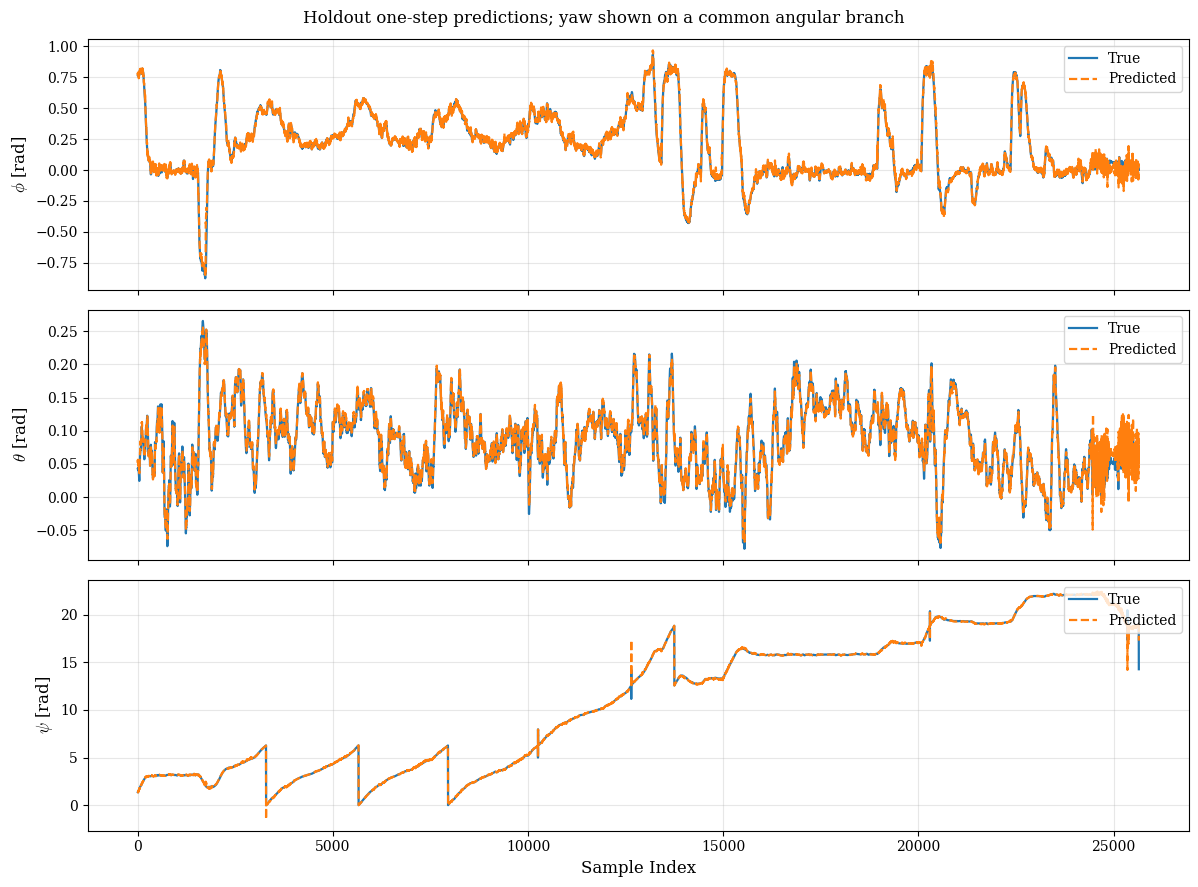

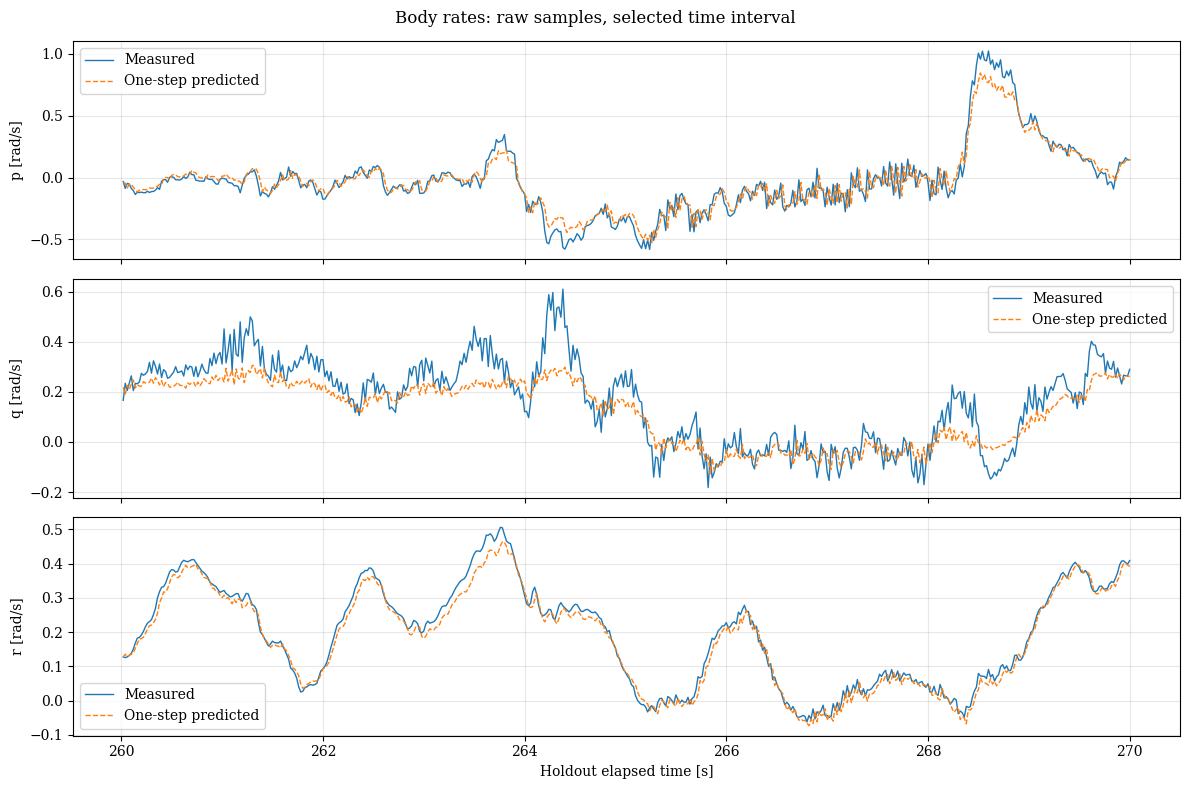

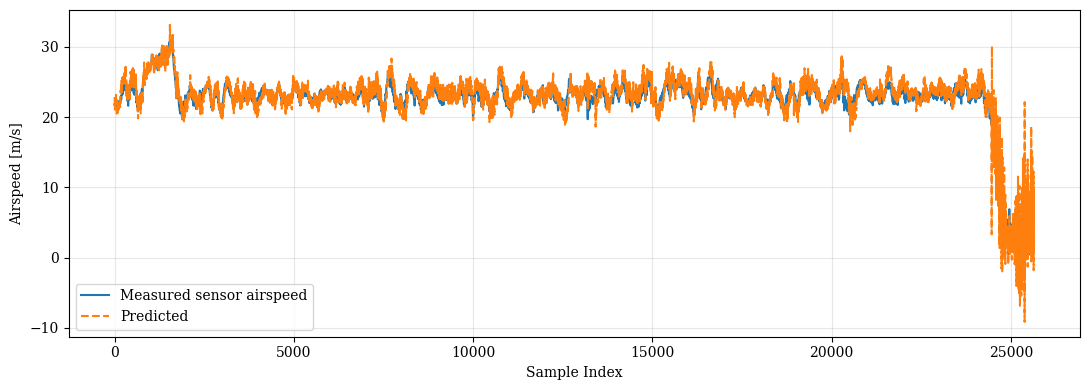

In [33]:
# Final holdout evaluation
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import savemat
import torch

plt.rcParams["text.usetex"] = False
plt.rcParams["mathtext.fontset"] = "cm"
plt.rcParams["font.family"] = "serif"

ckpt = torch.load(SessionName + "-best.pt", map_location=device)
model.load_state_dict(ckpt["state_dict"])
model.eval()

with torch.no_grad():
    if Stable_A == 1:
        A_t = model._stable_A().detach().cpu()
    else:
        A_t = model.linA.weight.detach().cpu()
    B_t = model.linB.weight.detach().cpu()

A = A_t.numpy()
B = B_t.numpy()
dimA = A.shape[0]

C = np.zeros((num_state, dimA), dtype=float)
C[:, :num_state] = np.eye(num_state)

D = np.zeros((num_state, num_input), dtype=float)

savemat("Koopman_" + SessionName + ".mat", {
    "A": A,
    "B": B,
    "C": C,
    "D": D,
    "X_mean": X_mean,
    "X_std": X_std,
    "U_mean": U_mean,
    "U_std": U_std,
})

print("Saved:", "Koopman_" + SessionName + ".mat")
print("A:", A.shape, "B:", B.shape, "C:", C.shape, "D:", D.shape)

@torch.no_grad()
def strict_rollout_full(model, X0, U, T):
    model.eval()
    z = model.lift(X0)

    if Stable_A == 1:
        Aev = model._stable_A().detach()
    else:
        Aev = model.linA.weight.detach()
    Bev = model.linB.weight.detach()

    pred = torch.zeros((T, num_state), device=U.device)
    pred[0:1, :] = X0

    for k in range(T - 1):
        z_next = z @ Aev.T + U[k:k+1, :] @ Bev.T

        x_next = project_unit_circle(z_next[:, :num_state])

        pred[k+1:k+2, :] = x_next
        z = torch.cat([x_next, z_next[:, num_state:]], dim=1)

    return pred

X0 = Xholdout[0:1, :].to(device)
Uv = Uholdout.to(device)
Xtrue = Xholdout.to(device)
Tt = Xtrue.shape[0]

pred_strict = strict_rollout_full(model, X0, Uv, Tt)

strict_mse_norm = torch.mean((pred_strict - Xtrue) ** 2).item()
sin_mean_t = torch.as_tensor(X_mean[0, SIN_IDX], dtype=Xtrue.dtype, device=device)
cos_mean_t = torch.as_tensor(X_mean[0, COS_IDX], dtype=Xtrue.dtype, device=device)
sin_std_t = torch.as_tensor(X_std[0, SIN_IDX], dtype=Xtrue.dtype, device=device)
cos_std_t = torch.as_tensor(X_std[0, COS_IDX], dtype=Xtrue.dtype, device=device)
true_s = Xtrue[:, SIN_IDX] * sin_std_t + sin_mean_t
true_c = Xtrue[:, COS_IDX] * cos_std_t + cos_mean_t
strict_s = pred_strict[:, SIN_IDX] * sin_std_t + sin_mean_t
strict_c = pred_strict[:, COS_IDX] * cos_std_t + cos_mean_t
sc_true = torch.mean(true_s**2 + true_c**2).item()
sc_pred = torch.mean(strict_s**2 + strict_c**2).item()
strict_yaw_error = torch.atan2(strict_s * true_c - strict_c * true_s,
                                strict_s * true_s + strict_c * true_c)
strict_yaw_rmse_deg = torch.rad2deg(torch.sqrt(torch.mean(strict_yaw_error**2))).item()

print("STRICT recursive rollout MSE (normalized):", strict_mse_norm)
print(f"STRICT recursive yaw RMSE over {Tt} samples: {strict_yaw_rmse_deg:.3f} deg")
print(f"Physical mean(sin^2+cos^2): true={sc_true:.4f}, pred={sc_pred:.4f} (ideal ~1.0)")

with torch.no_grad():
    x_current = Xholdout.to(device)
    u_current = Uholdout.to(device)
    z_current = model.lift(x_current)
    if Stable_A == 1:
        A_one = model._stable_A().detach()
    else:
        A_one = model.linA.weight.detach()
    B_one = model.linB.weight.detach()
    lifted_one_step = z_current @ A_one.T + u_current @ B_one.T
    pred_plot = project_unit_circle(lifted_one_step[:, :num_state])
    true_plot = Yholdout.to(device)

one_step_mse = torch.mean((pred_plot - true_plot) ** 2).item()
one_step_yaw_rmse_deg = torch.rad2deg(torch.sqrt(yaw_phase_loss(true_plot, pred_plot))).item()
print("ONE-STEP state MSE (normalized):", one_step_mse)
print(f"ONE-STEP yaw RMSE: {one_step_yaw_rmse_deg:.3f} deg")

pred_np = pred_plot.detach().cpu().numpy()
true_np = true_plot.detach().cpu().numpy()

pred_phys = pred_np * X_std + X_mean
true_phys = true_np * X_std + X_mean

phi_t, phi_p = true_phys[:, 0], pred_phys[:, 0]
th_t,  th_p  = true_phys[:, 1], pred_phys[:, 1]
sin_t, sin_p = true_phys[:, 2], pred_phys[:, 2]
cos_t, cos_p = true_phys[:, 3], pred_phys[:, 3]
p_t,   p_p   = true_phys[:, 4], pred_phys[:, 4]
q_t,   q_p   = true_phys[:, 5], pred_phys[:, 5]
r_t,   r_p   = true_phys[:, 6], pred_phys[:, 6]

psi_t_wrapped = np.arctan2(sin_t, cos_t)
psi_p_wrapped = np.arctan2(sin_p, cos_p)

psi_t = np.unwrap(psi_t_wrapped)
# Use the measured branch for display; retain the signed shortest angular error.
# Independently unwrapping noisy predictions caused a spurious 2*pi shift.
yaw_error_rad = np.arctan2(np.sin(psi_p_wrapped - psi_t_wrapped),
                           np.cos(psi_p_wrapped - psi_t_wrapped))
psi_p = psi_t + yaw_error_rad
independent_branch = np.rint((np.unwrap(psi_p_wrapped) - psi_t - yaw_error_rad) / (2*np.pi))
print("Independent yaw-unwrap branch changes at sample indices:",
      np.flatnonzero(np.diff(independent_branch) != 0))

Tplot = true_phys.shape[0]
t_idx = np.arange(Tplot)

fig1, axes1 = plt.subplots(3, 1, sharex=True, figsize=(12, 9))

attitude_series = [
    (r"$\phi$ [rad]",   phi_t, phi_p),
    (r"$\theta$ [rad]", th_t,  th_p),
    (r"$\psi$ [rad]",   psi_t, psi_p),
]

for ax, (label, yt, yp) in zip(axes1, attitude_series):
    ax.plot(t_idx, yt, label="True", linestyle="solid", linewidth=1.6)
    ax.plot(t_idx, yp, label="Predicted", linestyle="dashed", linewidth=1.6)
    ax.set_ylabel(label, fontsize=12)
    ax.grid(True, alpha=0.3)
    ax.legend(loc="upper right", fontsize=10)

axes1[-1].set_xlabel(r"Sample Index", fontsize=12)
fig1.suptitle("Holdout one-step predictions; yaw shown on a common angular branch")
fig1.tight_layout()


# One plot per body rate. Select a short interval to keep raw samples readable.
# Set RATE_PLOT_END_SECONDS = None to show the entire remaining holdout.
RATE_PLOT_START_SECONDS = 260.0
RATE_PLOT_END_SECONDS = 270.0
rate_time = np.arange(len(true_phys)) * dt
rate_window = rate_time >= RATE_PLOT_START_SECONDS
if RATE_PLOT_END_SECONDS is not None:
    rate_window &= rate_time <= RATE_PLOT_END_SECONDS
if not rate_window.any():
    raise ValueError("The selected rate-plot interval contains no holdout samples.")

fig2, axes2 = plt.subplots(3, 1, sharex=True, figsize=(12, 8))
for ax, index, label in zip(axes2, [4, 5, 6], ["p", "q", "r"]):
    ax.plot(rate_time[rate_window], true_phys[rate_window, index],
            label="Measured", linewidth=1.0)
    ax.plot(rate_time[rate_window], pred_phys[rate_window, index],
            "--", label="One-step predicted", linewidth=1.0)
    ax.set_ylabel(f"{label} [rad/s]")
    ax.grid(alpha=0.3)
    ax.legend()
axes2[-1].set_xlabel("Holdout elapsed time [s]")
fig2.suptitle("Body rates: raw samples, selected time interval")
fig2.tight_layout()

fig3, ax3 = plt.subplots(figsize=(11, 4))
sample_index = np.arange(len(true_phys))
ax3.plot(sample_index, true_phys[:, 7], label="Measured sensor airspeed")
ax3.plot(sample_index, pred_phys[:, 7], "--", label="Predicted")
ax3.set(xlabel="Sample Index", ylabel="Airspeed [m/s]")
ax3.legend(); ax3.grid(alpha=0.3); fig3.tight_layout()

import json
from pathlib import Path
persistence_phys = Xholdout.numpy() * X_std + X_mean
strict_phys = pred_strict.detach().cpu().numpy() * X_std + X_mean
strict_true_phys = Xholdout.numpy() * X_std + X_mean
metrics = {
    "partition": "Final 15%, untouched during fitting and checkpoint selection",
    "state_names": state_names,
    "one_step_rmse": np.sqrt(np.mean((pred_phys-true_phys)**2, axis=0)).tolist(),
    "persistence_one_step_rmse": np.sqrt(np.mean((persistence_phys-true_phys)**2, axis=0)).tolist(),
    "strict_projected_rollout_rmse": np.sqrt(np.mean((strict_phys-strict_true_phys)**2, axis=0)).tolist(),
    "holdout_samples": len(true_phys), "dt": dt,
    "one_step_circular_yaw_rmse_deg": float(one_step_yaw_rmse_deg),
    "strict_circular_yaw_rmse_deg": float(strict_yaw_rmse_deg),
    "yaw_display": "Measured unwrap plus signed circular prediction error; predictions unchanged",
}

z_linear = model.lift(Xholdout[:1].to(device)).detach().cpu().numpy()[0].astype(float)
linear_states = np.empty_like(strict_true_phys)
for k in range(len(linear_states)):
    linear_states[k] = (C @ z_linear) * X_std[0] + X_mean[0]
    z_linear = A @ z_linear + B @ Uholdout[k].numpy()
metrics["raw_ABCD_rollout_rmse"] = np.sqrt(np.mean((linear_states-strict_true_phys)**2, axis=0)).tolist()
metrics["spectral_radius_A"] = float(np.max(np.abs(np.linalg.eigvals(A))))
Path(SessionName + "_revised_validation_metrics.json").write_text(json.dumps(metrics, indent=2) + "\n")
print("Airspeed holdout one-step RMSE [m/s]:", metrics["one_step_rmse"][7])
print("Airspeed persistence RMSE [m/s]:", metrics["persistence_one_step_rmse"][7])
print("Airspeed raw ABCD rollout RMSE [m/s]:", metrics["raw_ABCD_rollout_rmse"][7])
for j, fig in enumerate((fig1, fig2, fig3), start=1):
    fig.savefig(f"{SessionName}_revised_holdout_{j}.png", dpi=140)
plt.show()


In [35]:
# Export normalized-state matrices and the matching checkpoint.
import numpy as np
import torch
from scipy.io import savemat

ckpt_path = SessionName + "-best.pt"
ckpt = torch.load(ckpt_path, map_location=device)

if "state_dict" in ckpt:
    model.load_state_dict(ckpt["state_dict"])
else:
    raise KeyError("Checkpoint does not contain 'state_dict'.")

model.eval()

with torch.no_grad():
    if Stable_A == 1:
        A_t = model._stable_A().detach().cpu()
    else:
        A_t = model.linA.weight.detach().cpu()
    B_t = model.linB.weight.detach().cpu()

A = A_t.numpy()
B = B_t.numpy()

dimA = A.shape[0]
assert A.shape == (dimA, dimA)
assert B.shape[0] == dimA and B.shape[1] == num_input

C = np.zeros((num_state, dimA), dtype=float)
C[:, :num_state] = np.eye(num_state)

D = np.zeros((num_state, num_input), dtype=float)

assert C.shape == (num_state, dimA)
assert D.shape == (num_state, num_input)

mat_name = "Koopman_ABCD_October.mat"
archive_mat_name = "Koopman_ABCD_" + SessionName + ".mat"
mat_payload = {
    "A": A,
    "B": B,
    "C": C,
    "D": D,
    "sample_time": np.array([[float(dt)]], dtype=float),
    "koopman_dimension": np.array([[dimA]], dtype=np.int32),
    "state_names": np.asarray(state_names, dtype=object),
    "state_units": np.asarray(state_units, dtype=object),
    "airspeed_column": airspeed_column,
    "selected_segment": selected_segment,
    "coordinate_convention": "z=[normalized measured states; encoder features]; x_phys=(Cz)*X_std+X_mean",
    "rollout_note": "Raw ABCD is linear. Yaw-circle projection in notebook is an extra nonlinear operation.",
    "input_names": np.asarray(input_names, dtype=object),
    "data_file": str(DATA_FILE),
    "data_archive": str(DATA_ARCHIVE),
    "max_time_seconds": MAX_TIME_SECONDS,
    "sensor_health_status": sensor_health_status,
    "actuator_offsets": actuator_offsets,
    "actuator_scales": actuator_scales,
    "time_column": time_column,
    "actuator_columns": np.asarray(actuator_columns, dtype=object),
    "X_mean": np.asarray(X_mean, dtype=float),
    "X_std":  np.asarray(X_std, dtype=float),
    "U_mean": np.asarray(U_mean, dtype=float),
    "U_std":  np.asarray(U_std, dtype=float),
}
savemat(mat_name, mat_payload, do_compression=True)
savemat(archive_mat_name, mat_payload, do_compression=True)

torch.save(ckpt, SessionName + "-export.pt")
print("Saved matching checkpoint:", SessionName + "-export.pt")

print("Saved:", mat_name)
print("Archived as:", archive_mat_name)
print("A:", A.shape, "B:", B.shape, "C:", C.shape, "D:", D.shape)
print("A = ", A)
print("B = ", B)
print("C = ", C)
print("D = ", D)


Saved matching checkpoint: Tiguar_20261009_airspeed_until3420s_Koopman_N32_uC1-elv-rud_Acttanh_StableA1-export.pt
Saved: Koopman_ABCD_Tiguar_20261009_airspeed_until3420s.mat
Archived as: Koopman_ABCD_Tiguar_20261009_airspeed_until3420s_Koopman_N32_uC1-elv-rud_Acttanh_StableA1.mat
A: (32, 32) B: (32, 8) C: (8, 32) D: (8, 8)
A =  [[ 0.5307405  -0.10289118 -0.00408256 ... -0.0203638  -0.15681662
  -0.06352971]
 [-0.11552166  0.85986096  0.01808145 ... -0.04515167  0.15853894
   0.04561718]
 [ 0.05269708  0.17451303  0.78537196 ...  0.34120947  0.23921943
   0.4175449 ]
 ...
 [-0.01498464  0.14357135  0.30494994 ... -0.05367607  0.18462403
   0.35259572]
 [-0.04892752 -0.436772   -0.01453723 ... -0.02536537 -0.01522329
  -0.10944641]
 [-0.06466421 -0.48636225 -0.07890113 ... -0.17445612 -0.23072715
  -0.20292564]]
B =  [[ 3.46728206e-01 -1.47132343e-02  1.72144175e-02 -2.30051816e-01
  -3.00569218e-02 -1.11153908e-01  2.07916666e-02 -5.02285585e-02]
 [-5.66048212e-02 -2.56091240e-03 -2.423

Controller: bounded sequentially linearized attitude MPC with idealized yaw loop
MPC solver failures: 0
Retained idealized simulation: imposed yaw response and commanded-speed position update.
Airspeed remains a model state but is not tracked by this original attitude MPC.
This trajectory plot does not validate learned yaw or airspeed tracking.
A/B/C/D: (32, 32) (32, 8) (8, 32) (8, 8)
Active identified inputs: ['phiD', 'thetaD', 'ThO', 'C1', 'elv', 'rud']
Position RMSE [x,y,z] (m): [0.00554275 0.00145134 0.0010004 ]
3D position RMSE (m): 0.0058162956159829035
Maximum 3D position error (m): 0.007579985140611808
Yaw-reference RMSE (deg): 0.1089178037305073
Input-bound activity fraction: [1.11111111e-04 1.36333333e-01 2.84444444e-02 0.00000000e+00
 1.51111111e-02 8.22222222e-03]


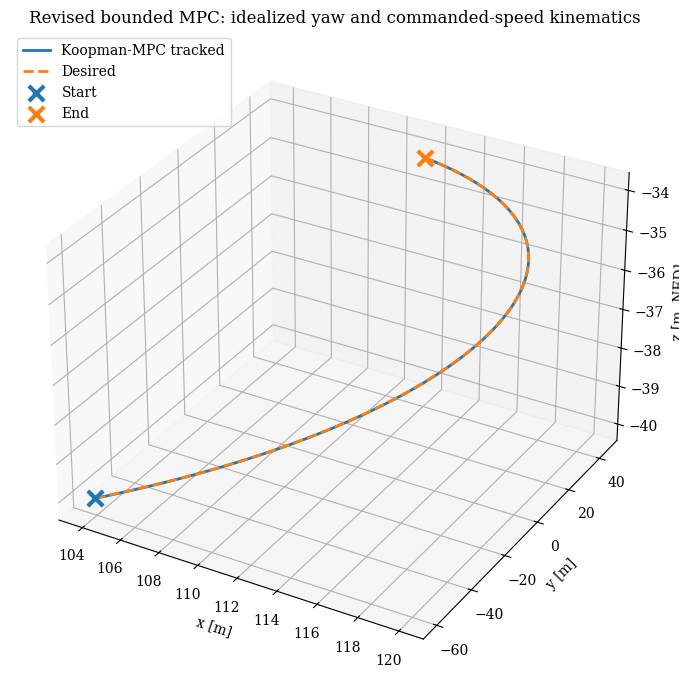

In [36]:

import numpy as np
import torch
import matplotlib.pyplot as plt

required = ["model", "A", "B", "C", "D", "X_mean", "X_std",
            "U_mean", "U_std", "U_std_raw", "Utrain", "dt", "project_unit_circle"]
missing = [name for name in required if name not in globals()]
if missing:
    raise NameError(f"Run Blocks 1-7 first. Missing: {missing}")

A_mpc = np.asarray(A, dtype=float)
B_mpc = np.asarray(B, dtype=float)
C_mpc = np.asarray(C, dtype=float)
D_mpc = np.asarray(D, dtype=float)
X_mean_np = np.asarray(X_mean, dtype=float).reshape(-1)
X_std_np = np.asarray(X_std, dtype=float).reshape(-1)
U_mean_np = np.asarray(U_mean, dtype=float).reshape(-1)
U_std_np = np.asarray(U_std, dtype=float).reshape(-1)
dt_model = float(dt)
n_z, n_u = B_mpc.shape
n_x = C_mpc.shape[0]
assert A_mpc.shape == (n_z, n_z)
assert C_mpc.shape == (n_x, n_z)
assert D_mpc.shape == (n_x, n_u)

active_u = np.flatnonzero(U_std_raw[0] > 1e-6)
B_active = B_mpc[:, active_u]
Utrain_active = Utrain.detach().cpu().numpy()[:, active_u]
u_lower = np.quantile(Utrain_active, 0.001, axis=0)
u_upper = np.quantile(Utrain_active, 0.999, axis=0)

# Sequentially linearized, bounded, constant-move-horizon MPC.
# The plant re-lifts after each step; predictions must include that operation.
from scipy.optimize import minimize

if params["activation"] != "tanh":
    raise ValueError("This MPC lift/Jacobian implementation requires the notebook's tanh encoder.")
encoder_weights = [layer.weight.detach().cpu().numpy().astype(float)
                   for layer in model.lift.aux_layers]

def lift_numpy(x):
    h = x
    for weight in encoder_weights:
        h = np.tanh(weight @ h)
    return np.concatenate([x, h])

def lift_jacobian_numpy(x):
    h, jac = x, np.eye(n_x)
    for weight in encoder_weights:
        h = np.tanh(weight @ h)
        jac = (1.0 - h*h)[:, None] * (weight @ jac)
    return np.vstack([np.eye(n_x), jac])

# Verify that the prediction encoder agrees with the trained encoder.
with torch.no_grad():
    probe = Xtrain[0].numpy().astype(float)
    np.testing.assert_allclose(lift_numpy(probe),
        model.lift(torch.tensor(probe[None], dtype=torch.float32, device=device)).cpu().numpy()[0],
        rtol=1e-5, atol=1e-6)

mpc_horizon = 15  # 0.30 seconds at the logged 50 Hz rate
move_penalty = 1e-5
B_state_active = (C_mpc @ B_mpc)[:, active_u]
mpc_previous_u = np.clip(np.zeros(len(active_u)), u_lower, u_upper)
mpc_solver_failures = 0

def constrained_mpc_move(x_now, attitude_reference, next_yaw):
    """Optimize a bounded constant command over a locally linearized horizon.

    Only roll and pitch are controlled by this attitude MPC. The existing ideal
    yaw loop is a known external operation, not an identified control response.
    Zero rate targets are omitted: they conflicted with feasible attitude trim.
    """
    global mpc_previous_u, mpc_solver_failures
    transition = C_mpc @ A_mpc
    F_local = transition @ lift_jacobian_numpy(x_now)
    offset = transition @ lift_numpy(x_now) - F_local @ x_now
    G_local = B_state_active.copy()
    # Match the plant's imposed yaw; freeze its next value over this short horizon.
    F_local[2:4] = 0.0
    G_local[2:4] = 0.0
    offset[2:4] = (np.array([np.sin(next_yaw), np.cos(next_yaw)])
                    - X_mean_np[2:4]) / X_std_np[2:4]
    target = (np.asarray(attitude_reference) - X_mean_np[:2]) / X_std_np[:2]
    free = x_now.copy()
    sensitivity = np.zeros((n_x, len(active_u)))
    design, residual = [], []
    for _ in range(mpc_horizon):
        free = F_local @ free + offset
        sensitivity = F_local @ sensitivity + G_local
        design.append(sensitivity[:2])
        residual.append(free[:2] - target)
    design = np.vstack(design)
    residual = np.concatenate(residual)
    hessian = design.T @ design + move_penalty * np.eye(len(active_u))
    linear = design.T @ residual - move_penalty * mpc_previous_u

    result = minimize(
        lambda control: (0.5 * control @ hessian @ control + linear @ control,
                         hessian @ control + linear),
        mpc_previous_u, jac=True, bounds=list(zip(u_lower, u_upper)),
        method="L-BFGS-B", options={"ftol": 1e-12, "gtol": 1e-8, "maxiter": 60})
    if not result.success or not np.isfinite(result.x).all():
        mpc_solver_failures += 1
        raise RuntimeError(f"MPC optimization failed: {result.message}")
    mpc_previous_u = result.x.copy()
    return result.x

path_radius = 120.0
path_rate = 0.005
path_z0 = -40.0
path_z_amplitude = 6.0
path_z_rate = 0.01
path_phase = np.deg2rad(-30.0)
position_feedback_gain = 0.20
max_correction_speed = 0.075

def desired_path(t_now):
    path_angle = path_rate * t_now + path_phase
    return np.array([
        path_radius * np.cos(path_angle),
        path_radius * np.sin(path_angle),
        path_z0 + path_z_amplitude * np.sin(path_z_rate * t_now),
    ], dtype=float)

def desired_velocity(t_now):
    path_angle = path_rate * t_now + path_phase
    return np.array([
        -path_radius * path_rate * np.sin(path_angle),
         path_radius * path_rate * np.cos(path_angle),
         path_z_amplitude * path_z_rate * np.cos(path_z_rate * t_now),
    ], dtype=float)

def guidance_reference(position, t_now):
    position_error = desired_path(t_now) - position
    correction_velocity = position_feedback_gain * position_error
    correction_norm = np.linalg.norm(correction_velocity)
    if correction_norm > max_correction_speed:
        correction_velocity *= max_correction_speed / correction_norm
    velocity_command = desired_velocity(t_now) + correction_velocity
    horizontal_speed = max(np.hypot(velocity_command[0], velocity_command[1]), 1e-9)
    speed_command = float(np.clip(np.linalg.norm(velocity_command), 0.45, 0.75))
    psi_ref = np.arctan2(velocity_command[1], velocity_command[0])
    theta_ref = np.clip(
        np.arctan2(-velocity_command[2], horizontal_speed), -0.20, 0.20
    )
    phi_ref = np.arctan(horizontal_speed**2 / (9.81 * path_radius))
    return float(phi_ref), float(theta_ref), float(psi_ref), float(speed_command)

T_sim = 180.0
num_steps = int(T_sim / dt_model)
position = desired_path(0.0)
psi0 = path_phase + np.pi / 2.0
x_phys = np.array([0.0, 0.0, np.sin(psi0), np.cos(psi0), 0.0, 0.0, 0.0, X_mean_np[7]])
x_norm = (x_phys - X_mean_np) / X_std_np
with torch.no_grad():
    x_tensor = torch.tensor(x_norm[None, :], dtype=torch.float32, device=device)
    z_lift = model.lift(x_tensor).detach().cpu().numpy().reshape(-1)

log_t = np.zeros(num_steps)
log_position = np.zeros((num_steps, 3))
log_desired_position = np.zeros((num_steps, 3))
log_state = np.zeros((num_steps, n_x))
log_reference = np.zeros((num_steps, 3))
log_u_active = np.zeros((num_steps, len(active_u)))

for k in range(num_steps):
    t_now = k * dt_model
    phi_ref, theta_ref, psi_ref, speed_command = guidance_reference(position, t_now)
    psi_model_now = np.arctan2(x_phys[2], x_phys[3])
    yaw_error = np.arctan2(np.sin(psi_ref - psi_model_now),
                           np.cos(psi_ref - psi_model_now))
    yaw_rate = np.clip(2.5 * yaw_error, -0.80, 0.80)
    psi_next = psi_model_now + dt_model * yaw_rate
    u_active_norm = constrained_mpc_move(x_norm, [phi_ref, theta_ref], psi_next)
    u_norm = np.zeros(n_u)
    u_norm[active_u] = u_active_norm

    # Apply the trained transition, then the retained idealized yaw operation.
    
    z_linear_next = A_mpc @ lift_numpy(x_norm) + B_mpc @ u_norm
    x_norm = C_mpc @ z_linear_next + D_mpc @ u_norm
    x_norm[2:4] = (np.array([np.sin(psi_next), np.cos(psi_next)])
                    - X_mean_np[2:4]) / X_std_np[2:4]
    if not np.isfinite(x_norm).all():
        raise FloatingPointError("Nonfinite state in MPC simulation")

    x_phys = x_norm * X_std_np + X_mean_np
    theta_now = x_phys[1]
    psi_now = np.arctan2(x_phys[2], x_phys[3])

    position += dt_model * speed_command * np.array([
        np.cos(theta_now) * np.cos(psi_now),
        np.cos(theta_now) * np.sin(psi_now),
        -np.sin(theta_now),
    ])

    log_t[k] = t_now + dt_model
    log_position[k] = position
    log_desired_position[k] = desired_path(t_now + dt_model)
    log_state[k] = x_phys
    log_reference[k] = [phi_ref, theta_ref, psi_ref]
    log_u_active[k] = u_active_norm

position_error = log_position - log_desired_position
rmse_xyz = np.sqrt(np.mean(position_error**2, axis=0))
rmse_3d = np.sqrt(np.mean(np.sum(position_error**2, axis=1)))
max_error_3d = np.max(np.linalg.norm(position_error, axis=1))
psi_model = np.arctan2(log_state[:, 2], log_state[:, 3])
psi_error = np.angle(np.exp(1j * (psi_model - log_reference[:, 2])))
yaw_rmse_deg = np.rad2deg(np.sqrt(np.mean(psi_error**2)))
saturation_fraction = np.mean(
    (log_u_active <= u_lower + 1e-7) | (log_u_active >= u_upper - 1e-7), axis=0
)

print("Controller: bounded sequentially linearized attitude MPC with idealized yaw loop")
print("MPC solver failures:", mpc_solver_failures)
print("Retained idealized simulation: imposed yaw response and commanded-speed position update.")
print("Airspeed remains a model state but is not tracked by this original attitude MPC.")
print("This trajectory plot does not validate learned yaw or airspeed tracking.")
print("A/B/C/D:", A_mpc.shape, B_mpc.shape, C_mpc.shape, D_mpc.shape)
print("Active identified inputs:", [input_names[j] for j in active_u])
print("Position RMSE [x,y,z] (m):", rmse_xyz)
print("3D position RMSE (m):", rmse_3d)
print("Maximum 3D position error (m):", max_error_3d)
print("Yaw-reference RMSE (deg):", yaw_rmse_deg)
print("Input-bound activity fraction:", saturation_fraction)

fig1 = plt.figure(figsize=(10, 7))
ax = fig1.add_subplot(111, projection="3d")
ax.plot(*log_position.T, label="Koopman-MPC tracked", linewidth=2)
ax.plot(*log_desired_position.T, "--", label="Desired", linewidth=2)
ax.scatter(*log_desired_position[0], marker="x", s=120, linewidths=3, label="Start")
ax.scatter(*log_desired_position[-1], marker="x", s=120, linewidths=3, label="End")
ax.set_xlabel("x [m]"); ax.set_ylabel("y [m]"); ax.set_zlabel("z [m, NED]")
ax.set_title("Revised bounded MPC: idealized yaw and commanded-speed kinematics")
ax.legend(loc="upper left")
fig1.tight_layout()
fig1.savefig(SessionName + "_mpc_revised_trajectory.png", dpi=140)
plt.show()
import json
from pathlib import Path
metrics_original_mpc = {
    "simulation": "Bounded attitude MPC; imposed yaw loop and commanded-speed kinematics",
    "controller": "Sequential linearization of re-lifted state map; constant move over 15 steps",
    "solver_failures": mpc_solver_failures,
    "input_bound_activity_fraction": saturation_fraction.tolist(),
    "active_inputs": [input_names[j] for j in active_u],
    "airspeed_tracking_enabled": False,
    "rmse_3d_m": float(rmse_3d), "rmse_xyz_m": rmse_xyz.tolist(),
    "maximum_error_m": float(max_error_3d), "yaw_rmse_deg": float(yaw_rmse_deg),
    "model_dt_s": dt_model, "duration_s": T_sim,
    "logging_convention": "Post-update position and reference both evaluated at t + dt",
}
Path(SessionName + "_mpc_revised_metrics.json").write_text(json.dumps(metrics_original_mpc, indent=2)+"\n")
np.savez_compressed(SessionName + "_mpc_revised_trajectory.npz", time=log_t, position=log_position,
                    desired_position=log_desired_position, state=log_state,
                    reference=log_reference, inputs_active=log_u_active,
                    u_lower=u_lower, u_upper=u_upper)
